# MPG Dataset – Heatmaps & Correlation Analysis
## Seaborn Session 7

This project analyzes vehicle fuel efficiency using Pearson and Spearman correlations, annotated heatmaps and ranked MPG correlations.

Task 1: Load MPG dataset and create basic heatmap

Total Rows: 392
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  

Pearson Correlation Matrix:
               mpg  cylinders  displacement  horsepower  weight  acceleration  \
mpg           1.00      -0.78         -0.81       -0.78   -0.83          0.42   
cylinders    -0.78       1.00          0.95        0.84    0.90         

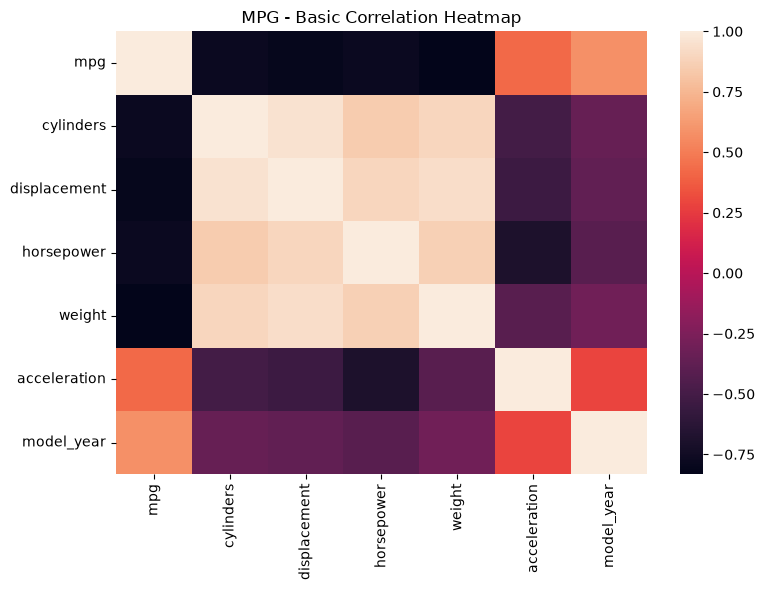

Task 1 Completed!


In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load MPG dataset
df = sns.load_dataset("mpg")

# Remove missing values
df = df.dropna().copy()

# Save cleaned dataset
df.to_csv("mpg_clean.csv", index=False)

print("Total Rows:", len(df))
print(df.head())

assert len(df) == 392

# Pearson correlation matrix
corr = df.corr(numeric_only=True)

print("\nPearson Correlation Matrix:")
print(corr.round(2))

# Basic heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(corr)

plt.title("MPG - Basic Correlation Heatmap")

plt.tight_layout()
plt.savefig("mpg_heatmap_basic.png", dpi=150)
plt.show()

print("Task 1 Completed!")


Task 2: Annotated correlation heatmap

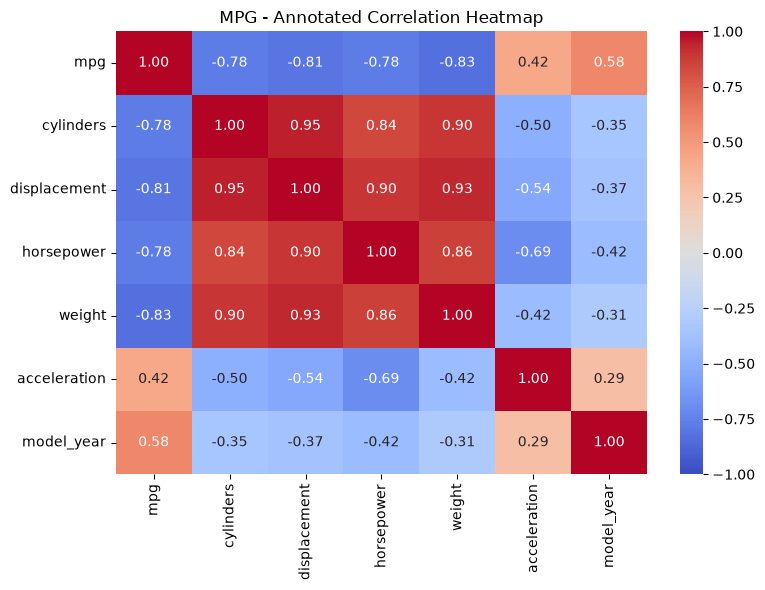

Task 2 Completed!


In [2]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("MPG - Annotated Correlation Heatmap")

plt.tight_layout()
plt.savefig("mpg_heatmap_annot.png", dpi=150)
plt.show()

print("Task 2 Completed!")


Task 3: Pearson vs Spearman heatmaps

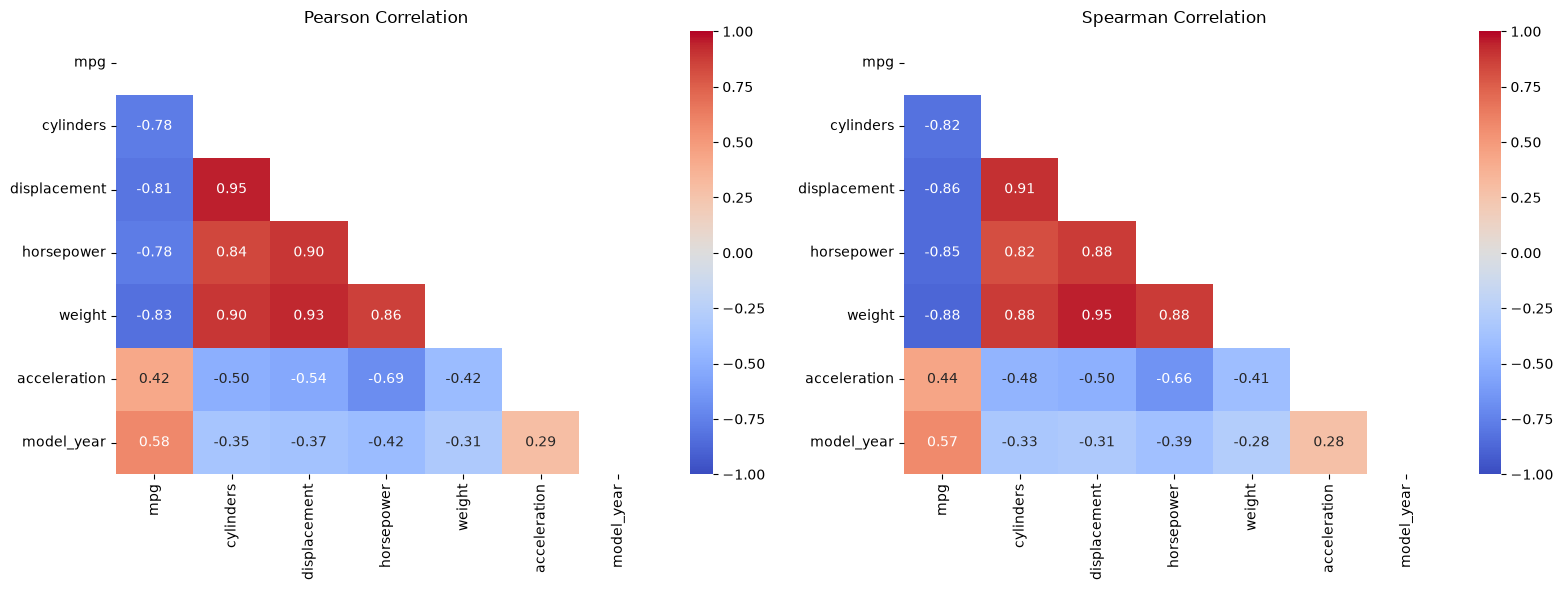

Task 3 Completed!


In [3]:

# Calculate correlation matrices
pearson_corr = df.corr(
    method="pearson",
    numeric_only=True
)

spearman_corr = df.corr(
    method="spearman",
    numeric_only=True
)

# Hide upper triangle
mask = np.triu(
    np.ones_like(pearson_corr, dtype=bool)
)

# Create two heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    pearson_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation")

sns.heatmap(
    spearman_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation")

plt.tight_layout()

plt.savefig(
    "mpg_pearson_vs_spearman.png",
    dpi=150
)

plt.show()

print("Task 3 Completed!")


Task 4: Final MPG correlation report

MPG CORRELATION RANKING
-----------------------------------
               mpg
mpg           1.00
model_year    0.58
acceleration  0.42
cylinders    -0.78
horsepower   -0.78
displacement -0.81
weight       -0.83


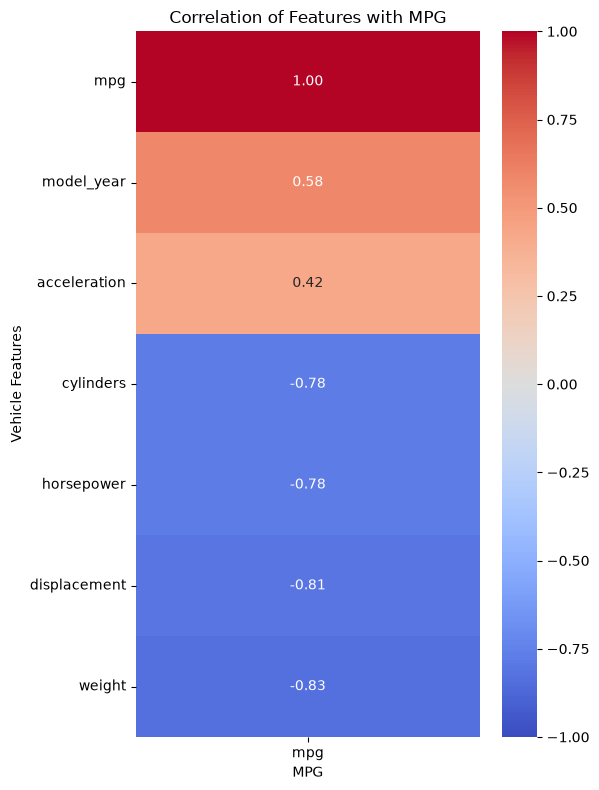

Task 4 Completed!
Session 7 Completed Successfully!


In [4]:

# Sort correlation with MPG
mpg_ranked = corr[["mpg"]].sort_values(
    "mpg",
    ascending=False
)

# Print ranked correlations
print("MPG CORRELATION RANKING")
print("-" * 35)

print(mpg_ranked.round(2))

# Save CSV
mpg_ranked.to_csv("mpg_corr_ranked.csv")

# Create one-column heatmap
plt.figure(figsize=(6, 8))

sns.heatmap(
    mpg_ranked,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation of Features with MPG")
plt.xlabel("MPG")
plt.ylabel("Vehicle Features")

plt.tight_layout()

plt.savefig(
    "mpg_corr_with_mpg.png",
    dpi=150
)

plt.show()

print("Task 4 Completed!")
print("Session 7 Completed Successfully!")
